In [1]:
import torch
from torchvision import datasets
from torchvision.transforms import ToTensor
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pathlib
import cv2
import matplotlib.pyplot as plt
from torchvision.transforms import ToTensor, Compose, Resize, Grayscale
from torchviz import make_dot

In [2]:
pathToModels = pathlib.Path("models")
pathToData = pathlib.Path("data")
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
TRANSFORM = Compose([
    Resize((28, 28)),
    Grayscale(num_output_channels=1),
    ToTensor()
])

In [4]:
trainDataset= datasets.MNIST(root=pathToData, train=True, download=True, transform=TRANSFORM)
testDataset= datasets.MNIST(root=pathToData, train=False, download=True, transform=TRANSFORM)
trainLoader = torch.utils.data.DataLoader(trainDataset, batch_size=BATCH_SIZE, shuffle=True)
testLoader = torch.utils.data.DataLoader(testDataset, batch_size=BATCH_SIZE, shuffle=False)

In [5]:
image = trainDataset[0][0].detach().cpu().numpy().squeeze()
image.shape, type(image), image.dtype, image.min(), image.max()

((28, 28), numpy.ndarray, dtype('float32'), np.float32(0.0), np.float32(1.0))

In [6]:
len(trainDataset), len(testDataset)

(60000, 10000)

In [7]:
IDX_CLASS = list()
for k, v in trainDataset.class_to_idx.items():
    IDX_CLASS.append((k, v))
print(IDX_CLASS)
IDX_CLASS.sort(
    key=lambda x: x[1]
)
CLASSES_NAMES = [x[0].split(' - ')[1] for x in IDX_CLASS]

[('0 - zero', 0), ('1 - one', 1), ('2 - two', 2), ('3 - three', 3), ('4 - four', 4), ('5 - five', 5), ('6 - six', 6), ('7 - seven', 7), ('8 - eight', 8), ('9 - nine', 9)]


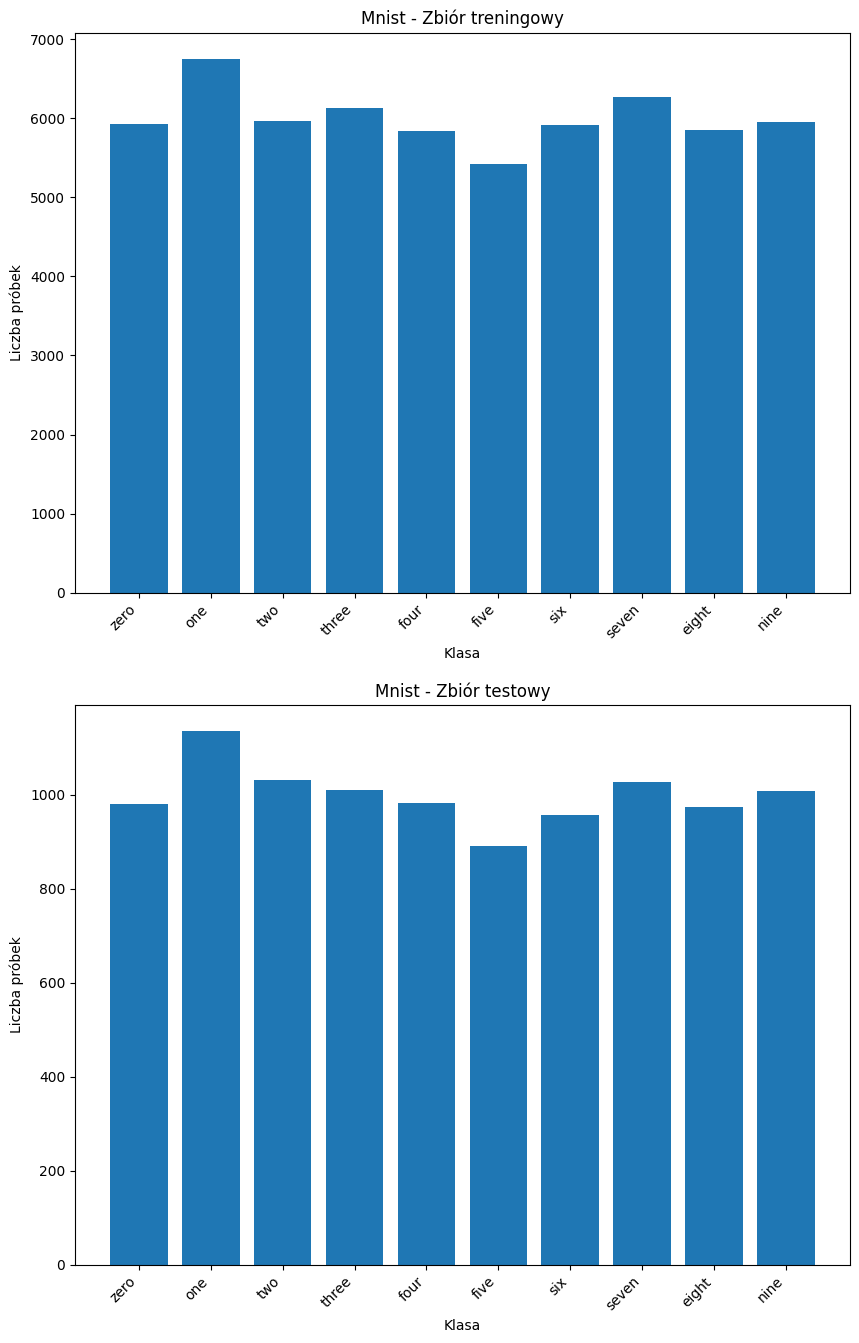

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(10, 16)) 

trainCounts = np.bincount([y for _, y in trainDataset])
axs[0].bar(range(len(trainCounts)), trainCounts)
axs[0].set_xticks(range(len(trainCounts)))
axs[0].set_xticklabels(CLASSES_NAMES, rotation=45, ha='right')
axs[0].set_title("Mnist - Zbiór treningowy")
axs[0].set_xlabel("Klasa")
axs[0].set_ylabel("Liczba próbek")

testCounts = np.bincount([y for _, y in testDataset])
axs[1].bar(range(len(testCounts)), testCounts)
axs[1].set_xticks(range(len(testCounts)))
axs[1].set_xticklabels(CLASSES_NAMES, rotation=45, ha='right')
axs[1].set_title("Mnist - Zbiór testowy")
axs[1].set_xlabel("Klasa")
axs[1].set_ylabel("Liczba próbek")


plt.show()

In [9]:
from models.mnist.model import mnistModel

In [10]:
from utils import *

In [11]:
model = mnistModel()

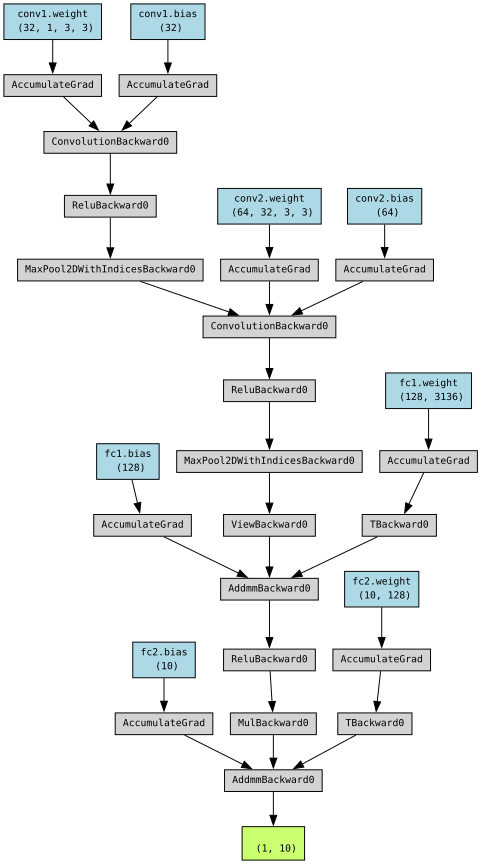

In [12]:
make_dot(model(torch.randn(1, 1, 28, 28)), params=dict(model.named_parameters()), show_attrs=False, show_saved=False)

In [23]:
model = mnistModel()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
model, train_losses, test_losses, train_accuracies, test_accuracies, best_epoch = train(model, trainLoader, testLoader, optimizer, criterion, DEVICE, 25, 'mnist')

Epoch 1/25 - Train Loss: 0.0045, Train Accuracy: 0.9090 - Test Loss: 0.0009, Test Accuracy: 0.9804
Epoch 2/25 - Train Loss: 0.0017, Train Accuracy: 0.9666 - Test Loss: 0.0007, Test Accuracy: 0.9857
Epoch 3/25 - Train Loss: 0.0013, Train Accuracy: 0.9755 - Test Loss: 0.0006, Test Accuracy: 0.9874
Epoch 4/25 - Train Loss: 0.0011, Train Accuracy: 0.9796 - Test Loss: 0.0005, Test Accuracy: 0.9891
Epoch 5/25 - Train Loss: 0.0009, Train Accuracy: 0.9821 - Test Loss: 0.0005, Test Accuracy: 0.9892
Epoch 6/25 - Train Loss: 0.0008, Train Accuracy: 0.9851 - Test Loss: 0.0005, Test Accuracy: 0.9889
Epoch 7/25 - Train Loss: 0.0007, Train Accuracy: 0.9855 - Test Loss: 0.0004, Test Accuracy: 0.9912
Epoch 8/25 - Train Loss: 0.0006, Train Accuracy: 0.9884 - Test Loss: 0.0004, Test Accuracy: 0.9919
Epoch 9/25 - Train Loss: 0.0006, Train Accuracy: 0.9887 - Test Loss: 0.0004, Test Accuracy: 0.9919
Epoch 10/25 - Train Loss: 0.0005, Train Accuracy: 0.9897 - Test Loss: 0.0005, Test Accuracy: 0.9908
Epoch 11/

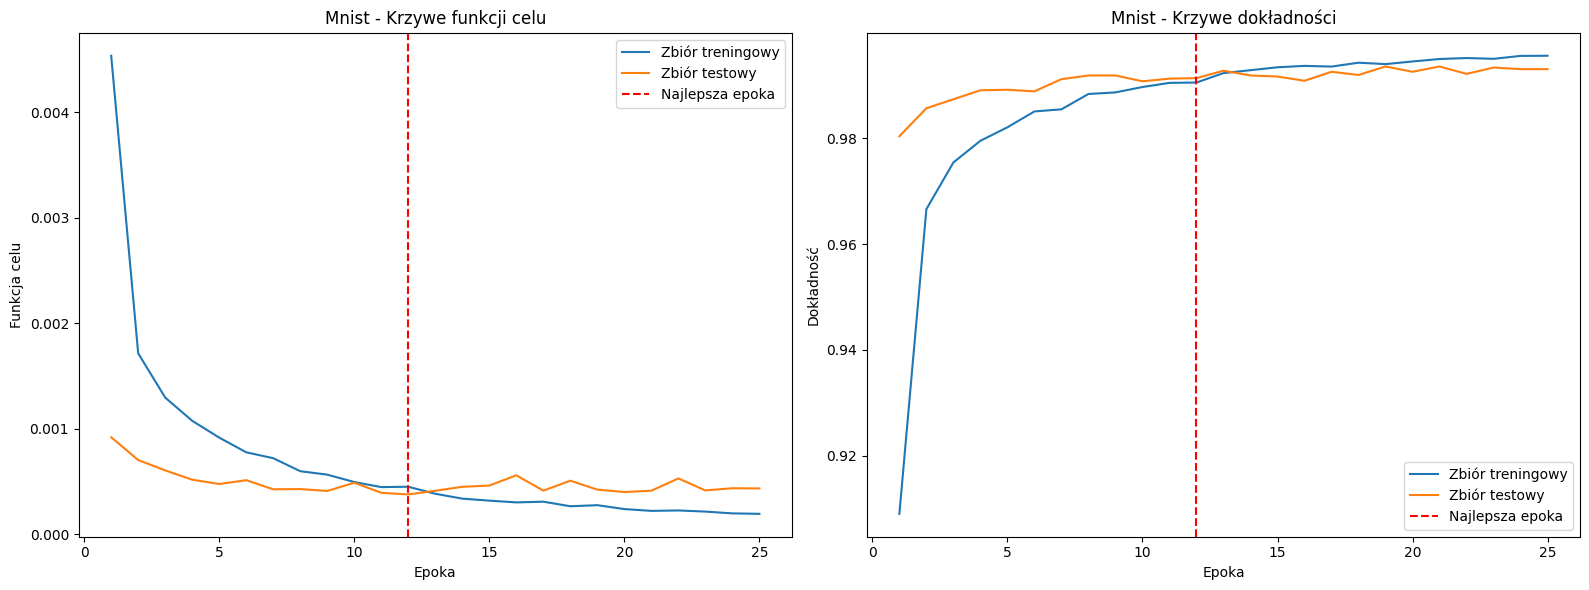

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))

axs[0].plot(range(1, len(train_losses)+1), train_losses, label='Zbiór treningowy')
axs[0].plot(range(1, len(test_losses)+1), test_losses, label='Zbiór testowy')
axs[0].set_title('Mnist - Krzywe funkcji celu')
axs[0].set_xlabel('Epoka')
axs[0].set_ylabel('Funkcja celu')
axs[0].axvline(x=best_epoch, color='r', linestyle='--', label='Najlepsza epoka')
axs[0].legend()

axs[1].plot(range(1, len(train_accuracies)+1), train_accuracies, label='Zbiór treningowy')
axs[1].plot(range(1, len(test_accuracies)+1), test_accuracies, label='Zbiór testowy')
axs[1].set_title('Mnist - Krzywe dokładności')
axs[1].set_xlabel('Epoka')
axs[1].set_ylabel('Dokładność')
axs[1].axvline(x=best_epoch, color='r', linestyle='--', label='Najlepsza epoka')
axs[1].legend()

plt.tight_layout()
plt.show()

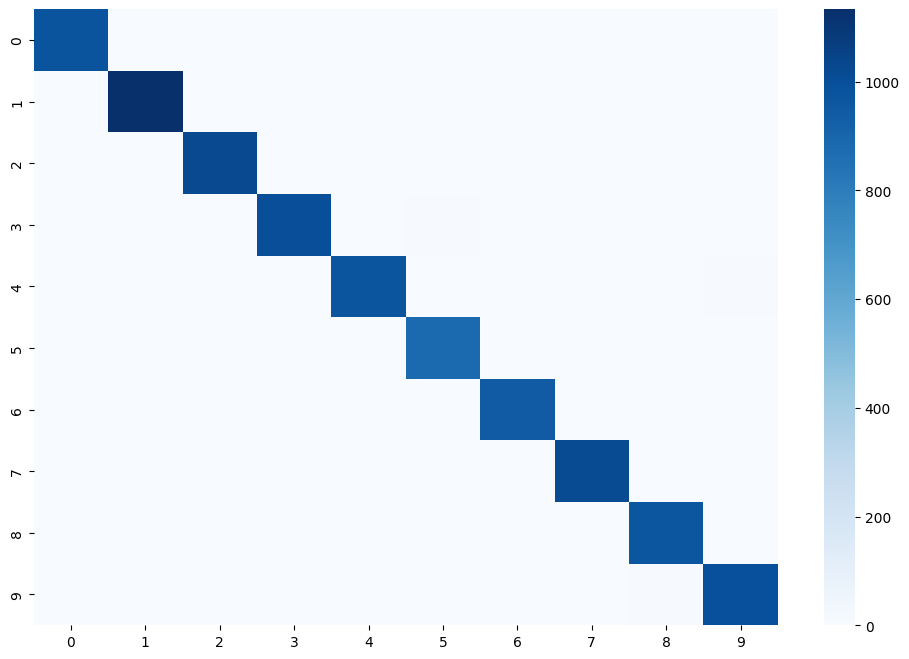

In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_true = []
y_pred = []
model.eval()
with torch.no_grad():
    for images, labels in testLoader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 8))
sns.heatmap(cm, cmap='Blues')
    
plt.show()